In [2]:
import numpy as np 


In [6]:
class logistic_regression:
    def __init__(self,lr=0.01,n_iters=1000):
        self.lr = lr
        self.n_iters = n_iters
        self.weights = None
        self.bias = None
    def fit(self,x,y):
        n_samples,n_features = x.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        for _ in range(self.n_iters):
            linear_model = np.dot(x,self.weights)+self.bias
            sigmoid = 1/(1+np.exp(-linear_model))
            dw = (1 / n_samples) * np.dot(x.T, (sigmoid - y))
            db = (1 / n_samples) * np.sum(sigmoid - y)
            self.weights -= self.lr * dw
            self.bias -= self.lr * db
    def predict(self,x):
        linear_model = np.dot(x,self.weights)+self.bias
        sigmoid = 1/(1+np.exp(-linear_model))
        sigmoid_cls =[1 if i > 0.5 else 0 for i in sigmoid]
        return sigmoid_cls
        

# TESTING THE MODEL 

In [11]:
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split 
dc = datasets.load_breast_cancer()
x_train, x_test, y_train, y_test = train_test_split(dc.data, dc.target, test_size=0.3, random_state=42)
regressor = logistic_regression(lr=0.01,n_iters=1000)
regressor.fit(x_train,y_train)
pr = regressor.predict(x_test)

C:\Users\yahya\AppData\Local\Temp\ipykernel_1644\102264757.py:13: RuntimeWarning: overflow encountered in exp
  sigmoid = 1/(1+np.exp(-linear_model))
C:\Users\yahya\AppData\Local\Temp\ipykernel_1644\102264757.py:20: RuntimeWarning: overflow encountered in exp
  sigmoid = 1/(1+np.exp(-linear_model))


# Evaluate and display results

In [13]:
def accuracy(y_true,y_pred):
    accuracy = np.sum(y_true==y_pred)/len(y_true)
    return accuracy

print("Accuracy:", accuracy(y_test, pr))

Accuracy: 0.9298245614035088


Accuracy: 0.9298245614035088


C:\Users\yahya\AppData\Local\Temp\ipykernel_1644\102264757.py:20: RuntimeWarning: overflow encountered in exp
  sigmoid = 1/(1+np.exp(-linear_model))


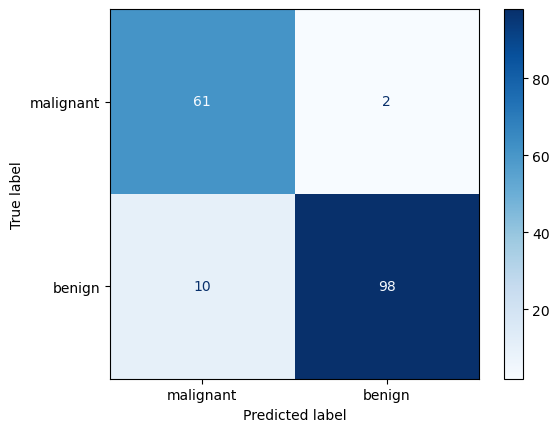

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
pr = regressor.predict(x_test)
print("Accuracy:", accuracy(y_test, pr))

cm = confusion_matrix(y_test, pr)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dc.target_names
)
display.plot(cmap="Blues", values_format="d")
